# Vibe Quest S14 · ¿Cuándo conviene un ViT y cuándo una CNN? (CIFAR-10 con 100, 1000 y 10000 imágenes)

**Consigna.** Comparar un Vision Transformer (ViT) y una CNN en CIFAR-10 con subconjuntos de 100, 1000 y 10000 imágenes, visualizar mapas de atención frente a mapas de características y determinar experimentalmente cuándo conviene cada arquitectura según la cantidad de datos.

**Cómo lo resolvemos.** Usamos dos modelos preentrenados y congelados de escala parecida (ViT-S/16 y ConvNeXt-T), extraemos sus rasgos una sola vez y entrenamos sobre ellos una sonda lineal (*linear probe*) con cada subconjunto. Así se mantiene igual todo lo que depende de nosotros (datos, preprocesamiento, sonda y evaluación); lo que no se puede igualar es la receta con la que cada modelo fue preentrenado, y eso se discute en la sección 3.1. Las decisiones de diseño y sus fuentes están en la sección 3 y en la sección final de fuentes.

**Cómo usar este cuaderno.** Entorno de ejecución con GPU T4 (Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4). Ejecuta todo en orden; el conjunto de datos se descarga solo. Los paneles con controles deslizantes están en las secciones 5.6, 6.4, 8.5 y 8.7.

# 1 · Preparación

## 1.1 · Instalar librerías
`timm` (Wightman, 2019) trae los modelos preentrenados y `datasets` descarga CIFAR-10 desde Hugging Face.

In [69]:
# Instalación silenciosa de las dos librerías que Colab no trae por defecto
!pip install -q timm datasets

## 1.2 · Importar librerías

In [70]:
import time, warnings

import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import timm
from datasets import load_dataset
from sklearn.model_selection import StratifiedKFold
import ipywidgets as widgets
from IPython.display import display, clear_output

warnings.filterwarnings("ignore", category=FutureWarning)   # solo los avisos de funciones que cambiarán en versiones futuras

## 1.3 · Parámetros del experimento
Todo lo que se puede cambiar está en esta celda. `TAMANOS_PEDIDOS` son los tres tamaños de la consigna; los demás completan la curva de datos.

In [137]:
SEMILLAS = [0, 1, 2]                      # cada semilla elige otro subconjunto de entrenamiento
TAMANOS_PEDIDOS = [100, 1000, 10000]      # tamaños que pide la consigna
TAMANOS = [30, 100, 300, 1000, 3000, 10000]  # curva completa (incluye los pedidos)

# Pesos preentrenados de timm: los dos vieron ImageNet-21k/22k y se ajustaron en ImageNet-1k
MODELOS = {
    "ViT-S/16":   "vit_small_patch16_224.augreg_in21k_ft_in1k",
    "ConvNeXt-T": "convnext_tiny.fb_in22k_ft_in1k",
}

LAMBDAS = [1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0]   # penalización L2 de la sonda (se elige por validación cruzada)
N_BOOT = 2000                             # remuestreos para los intervalos de confianza
BATCH = 256                               # imágenes por lote al extraer rasgos
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

RESULTADOS = {}                           # aquí se guardan las tablas para exportarlas al final

## 1.4 · Verificar la GPU
Sin GPU la extracción de rasgos tarda decenas de minutos, así que la celda se detiene con un aviso claro.

In [72]:
if DEVICE != "cuda":
    raise RuntimeError("No hay GPU. Ve a Entorno de ejecución → Cambiar tipo de entorno de ejecución y elige T4.")
print("GPU:", torch.cuda.get_device_name(0))
import datasets, sklearn
print("torch", torch.__version__, "| timm", timm.__version__, "| datasets", datasets.__version__, "| scikit-learn", sklearn.__version__)   # versiones usadas, para poder reproducir

GPU: Tesla T4
torch 2.14.1+cu130 | timm 1.0.31 | datasets 4.8.5 | scikit-learn 1.6.1
GPU: Tesla T4
torch 2.14.1+cu130 | timm 1.0.31 | datasets 4.8.5 | scikit-learn 1.6.1


# 2 · Datos: CIFAR-10
CIFAR-10 (Krizhevsky, 2009) tiene 60000 imágenes de 32×32 en 10 clases: 50000 de entrenamiento y 10000 de prueba. Se descarga desde Hugging Face, de la organización `uoft-cs` (https://huggingface.co/datasets/uoft-cs/cifar10); la página original de los autores es https://www.cs.toronto.edu/~kriz/cifar.html. Los subconjuntos de 100, 1000 y 10000 imágenes se sacan siempre del conjunto de entrenamiento y la evaluación se hace siempre sobre las 10000 imágenes de prueba.

## 2.1 · Descargar el conjunto de datos

In [73]:
cifar10 = load_dataset("uoft-cs/cifar10")

## 2.2 · Revisar tamaños y clases

In [74]:
CLASES = cifar10["train"].features["label"].names
print("entrenamiento:", len(cifar10["train"]), "imágenes")
print("prueba:", len(cifar10["test"]), "imágenes")
print("clases:", CLASES)

entrenamiento: 50000 imágenes
prueba: 10000 imágenes
clases: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
entrenamiento: 50000 imágenes
prueba: 10000 imágenes
clases: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


## 2.3 · Convertir a arreglos de NumPy
Pasamos las imágenes a arreglos `uint8` de forma (N, 32, 32, 3) para trabajar rápido en la GPU.

In [75]:
def a_arreglos(particion):
    # Convierte cada imagen PIL en un arreglo y apila todo en un solo tensor
    X = np.stack([np.array(im) for im in particion["img"]])
    y = np.array(particion["label"])
    return X, y

In [76]:
Xtr, ytr = a_arreglos(cifar10["train"])
Xte, yte = a_arreglos(cifar10["test"])
print("Xtr", Xtr.shape, Xtr.dtype, "| Xte", Xte.shape)

Xtr (50000, 32, 32, 3) uint8 | Xte (10000, 32, 32, 3)
Xtr (50000, 32, 32, 3) uint8 | Xte (10000, 32, 32, 3)


## 2.4 · Una imagen por clase
Las imágenes son muy pequeñas: se las ve borrosas porque solo tienen 32×32 píxeles.

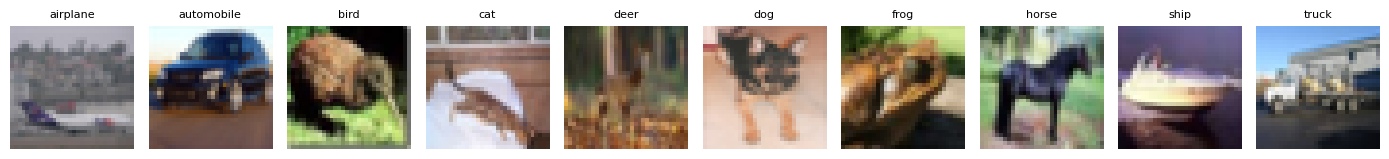

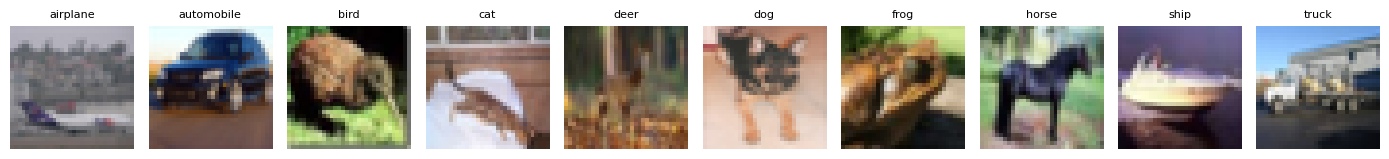

In [77]:
fig, ejes = plt.subplots(1, 10, figsize=(14, 1.8))
for k, eje in enumerate(ejes):
    idx = np.where(ytr == k)[0][0]       # primera imagen de la clase k
    eje.imshow(Xtr[idx])
    eje.set_title(CLASES[k], fontsize=8)
    eje.axis("off")
plt.tight_layout()
plt.show()

# 3 · Modelos preentrenados y congelados

## 3.1 · Qué comparamos y por qué
Comparamos **ViT-S/16** (`vit_small_patch16_224.augreg_in21k_ft_in1k`) y **ConvNeXt-T** (`convnext_tiny.fb_in22k_ft_in1k`). Las razones, con su respaldo:

| Decisión | Razón | Respaldo |
|---|---|---|
| Modelos de escala similar | ViT-S/16 tiene 22.1 M de parámetros y 4.6 GMAC; ConvNeXt-T, 29 M y 4.5 GMAC (cifras publicadas, con la cabeza de 1000 clases) | Touvron et al. (2022, Tabla 1, p. 4); Liu et al. (2022, Tabla 1, p. 7) |
| ConvNeXt como CNN | Es una CNN modernizada con la receta de los transformers; reentrenar un ResNet-50 con esa receta ya sube su exactitud de 76.1 % a 78.8 % sin cambiar la arquitectura | Liu et al. (2022, sec. 2.1, p. 3) |
| Mismo corpus de preentrenamiento | Los dos pesos vieron ImageNet-21k/22k y se ajustaron en ImageNet-1k, para que la diferencia no venga del corpus | fichas de los pesos en Hugging Face: ViT-S/16 (https://huggingface.co/timm/vit_small_patch16_224.augreg_in21k_ft_in1k, pesos de Steiner et al., 2021) y ConvNeXt-T (https://huggingface.co/timm/convnext_tiny.fb_in22k_ft_in1k, pesos de Liu et al., 2022) |
| Rasgos congelados y sonda lineal | Es el protocolo estándar para medir la calidad de los rasgos y la transferencia con pocos datos | Wang et al. (2022, Tabla 4, p. 8, y apéndice H.3, p. 22: capa lineal con normalización sobre el backbone congelado e hiperparámetros elegidos en un conjunto de validación; para pocos ejemplos usan regresión logística de scikit-learn) |
| Subconjuntos pequeños | Con pocos datos los ViT suelen rendir peor porque les falta sesgo inductivo (localidad); la brecha se reporta sobre todo entrenando desde cero | Lu et al. (2022, resumen y p. 1); Zhang et al. (2025, resumen); Rostand et al. (2025, resumen) |

**Límite que conviene tener presente.** Las fuentes de la última fila miden ViT entrenados desde cero; aquí los modelos ya vienen preentrenados, así que lo que medimos es la calidad de los rasgos con pocos datos, no el efecto de entrenar desde cero. Además, los dos pesos usaron recetas de preentrenamiento distintas (AugReg para el ViT y la receta de Liu et al. para ConvNeXt), por lo que parte de cualquier diferencia puede venir de la receta y no de la arquitectura (Liu et al., 2022, sec. 2.1).

Los parámetros de la sección 3.4 salen menores que los publicados porque se mide el extractor sin la cabeza de clasificación (384×1000+1000 ≈ 0.39 M en el ViT y 768×1000+1000 ≈ 0.77 M en ConvNeXt). Los GMAC que mide `FlopCounterMode` también pueden diferir de los de las fichas de timm (4.3 y 4.5), porque el contador incluye las multiplicaciones de la atención.

## 3.2 · Función para cargar un modelo
Quitamos la cabeza de ImageNet (`num_classes=0`) para que el modelo entregue directamente el vector de rasgos, lo ponemos en modo evaluación y congelamos todos sus pesos.

In [78]:
def cargar_modelo(nombre_timm):
    # pretrained=True baja los pesos de Hugging Face; num_classes=0 deja solo el extractor de rasgos
    modelo = timm.create_model(nombre_timm, pretrained=True, num_classes=0)
    modelo = modelo.to(DEVICE).eval()
    for p in modelo.parameters():
        p.requires_grad_(False)           # ningún peso del extractor se actualiza
    cfg = timm.data.resolve_data_config({}, model=modelo)   # media, desviación y tamaño de entrada
    return modelo, cfg

## 3.3 · Cargar los dos modelos

In [79]:
MOD = {nombre: cargar_modelo(timm_id) for nombre, timm_id in MODELOS.items()}
for nombre, (modelo, cfg) in MOD.items():
    print(nombre, "| entrada", cfg["input_size"], "| media", cfg["mean"], "| dimensión de rasgos", modelo.num_features)

ViT-S/16 | entrada (3, 224, 224) | media (0.5, 0.5, 0.5) | dimensión de rasgos 384
ConvNeXt-T | entrada (3, 224, 224) | media (0.485, 0.456, 0.406) | dimensión de rasgos 768
ViT-S/16 | entrada (3, 224, 224) | media (0.5, 0.5, 0.5) | dimensión de rasgos 384
ConvNeXt-T | entrada (3, 224, 224) | media (0.485, 0.456, 0.406) | dimensión de rasgos 768


## 3.4 · Parámetros y FLOPs de cada modelo
Contamos los FLOPs con `FlopCounterMode` y dividimos entre 2 para expresarlos como multiplicaciones-acumulaciones (MAC), que es la convención de Touvron et al. (2022) y Liu et al. (2022). Sirve para comprobar los valores publicados.

In [80]:
from torch.utils.flop_counter import FlopCounterMode

def contar_gflops(modelo):
    x = torch.randn(1, 3, 224, 224, device=DEVICE)
    with FlopCounterMode(display=False) as contador, torch.no_grad():
        modelo(x)
    return contador.get_total_flops() / 2 / 1e9     # FLOPs → MAC, en miles de millones

In [81]:
filas = []
for nombre, (modelo, cfg) in MOD.items():
    filas.append({
        "modelo": nombre,
        "parámetros (M)": round(sum(p.numel() for p in modelo.parameters()) / 1e6, 2),
        "GFLOPs (MAC)": round(contar_gflops(modelo), 2),
        "dim. de rasgos": modelo.num_features,
    })
tabla_modelos = pd.DataFrame(filas)
RESULTADOS["modelos"] = tabla_modelos
print(tabla_modelos.to_string(index=False))

    modelo  parámetros (M)  GFLOPs (MAC)  dim. de rasgos
  ViT-S/16           21.67          4.60             384
ConvNeXt-T           27.82          4.45             768
    modelo  parámetros (M)  GFLOPs (MAC)  dim. de rasgos
  ViT-S/16           21.67          4.60             384
ConvNeXt-T           27.82          4.45             768


# 4 · Extracción de rasgos
Cada imagen de 32×32 se agranda a 224×224 (interpolación bicúbica) y se normaliza con la media y desviación propias de cada modelo. Luego pasa por el extractor congelado y guardamos el vector de rasgos. Se extrae **una sola vez** para las 60000 imágenes; después todas las sondas trabajan sobre esos vectores, lo que hace barato probar muchos tamaños y semillas.

## 4.1 · Función de extracción

In [82]:
@torch.no_grad()
def extraer(modelo, cfg, X):
    media = torch.tensor(cfg["mean"], device=DEVICE).view(1, 3, 1, 1)
    desv = torch.tensor(cfg["std"], device=DEVICE).view(1, 3, 1, 1)
    salidas = []
    for i in range(0, len(X), BATCH):
        lote = torch.from_numpy(X[i:i + BATCH]).to(DEVICE).permute(0, 3, 1, 2).float() / 255
        lote = F.interpolate(lote, size=224, mode="bicubic", align_corners=False).clamp(0, 1)
        lote = (lote - media) / desv
        with torch.autocast("cuda", dtype=torch.float16):    # media precisión: más rápido y suficiente aquí
            f = modelo(lote)
        salidas.append(f.float().cpu())
    return torch.cat(salidas)

## 4.2 · Extraer los rasgos de CIFAR-10
Tarda unos dos o tres minutos en una T4. Medimos el tiempo y la memoria máxima de cada modelo para la comparación de eficiencia.

In [83]:
FEATS = {}      # (modelo, partición) → matriz de rasgos
EFIC = []       # tiempos y memoria por modelo
for nombre, (modelo, cfg) in MOD.items():
    torch.cuda.synchronize()
    torch.cuda.reset_peak_memory_stats()
    t0 = time.time()
    FEATS[(nombre, "train")] = extraer(modelo, cfg, Xtr)
    FEATS[(nombre, "test")] = extraer(modelo, cfg, Xte)
    torch.cuda.synchronize()
    dt = time.time() - t0
    EFIC.append({
        "modelo": nombre,
        "imágenes": len(Xtr) + len(Xte),
        "tiempo (s)": round(dt, 1),
        "imágenes/s": round((len(Xtr) + len(Xte)) / dt),
        "memoria GPU máx. (MiB)": round(torch.cuda.max_memory_allocated() / 2**20),
    })
    print(nombre, "listo en", round(dt, 1), "s")

ViT-S/16 listo en 60.0 s
ConvNeXt-T listo en 96.9 s
ViT-S/16 listo en 55.3 s
ConvNeXt-T listo en 96.8 s


## 4.3 · Tabla de eficiencia de la extracción

In [84]:
tabla_efic = pd.DataFrame(EFIC).merge(tabla_modelos, on="modelo")
RESULTADOS["eficiencia"] = tabla_efic
print(tabla_efic.to_string(index=False))

    modelo  imágenes  tiempo (s)  imágenes/s  memoria GPU máx. (MiB)  parámetros (M)  GFLOPs (MAC)  dim. de rasgos
  ViT-S/16     60000        60.0        1001                    1011           21.67          4.60             384
ConvNeXt-T     60000        96.9         619                    2404           27.82          4.45             768
    modelo  imágenes  tiempo (s)  imágenes/s  memoria GPU máx. (MiB)  parámetros (M)  GFLOPs (MAC)  dim. de rasgos
  ViT-S/16     60000        55.3        1085                    1212           21.67          4.60             384
ConvNeXt-T     60000        96.8         620                    2606           27.82          4.45             768


# 5 · Sonda lineal con 100, 1000 y 10000 imágenes
Para cada modelo, tamaño y semilla: se elige un subconjunto **balanceado** del entrenamiento (el mismo número de imágenes por clase), se estandarizan los rasgos con la media y la desviación de ese subconjunto y se entrena una regresión logística multinomial con penalización L2. La penalización se elige por validación cruzada de 3 particiones **dentro del subconjunto**, nunca con las imágenes de prueba. Los dos modelos reciben exactamente el mismo trato, como indica la lámina 99 de la Clase 14 (comparar arquitecturas exige igualar la receta de entrenamiento).

## 5.1 · Muestreo balanceado

In [85]:
def muestrear(y, n, semilla):
    # Elige n // (número de clases) imágenes por clase, al azar según la semilla
    rng = np.random.default_rng(semilla)
    clases = np.unique(y)
    por_clase = n // len(clases)
    return np.concatenate([rng.choice(np.where(y == k)[0], por_clase, replace=False) for k in clases])

## 5.2 · Sonda lineal en la GPU
Regresión logística multinomial entrenada con L-BFGS sobre todo el subconjunto a la vez (con tan pocos datos no hace falta hacer lotes).

In [86]:
def ajustar_sonda(X, y, lam, n_clases, iteraciones=200):
    # W y b son los únicos parámetros que se aprenden; el extractor sigue congelado
    W = torch.zeros(X.shape[1], n_clases, device=DEVICE, requires_grad=True)
    b = torch.zeros(n_clases, device=DEVICE, requires_grad=True)
    opt = torch.optim.LBFGS([W, b], lr=1, max_iter=iteraciones, line_search_fn="strong_wolfe")

    def cierre():
        opt.zero_grad()
        perdida = F.cross_entropy(X @ W + b, y) + lam * (W ** 2).sum()   # entropía cruzada + penalización L2
        perdida.backward()
        return perdida

    opt.step(cierre)
    return W.detach(), b.detach()

In [87]:
def elegir_lambda(X, y, n_clases):
    # Validación cruzada estratificada de 3 particiones: se queda con la penalización que más acierta
    kf = StratifiedKFold(n_splits=3, shuffle=True, random_state=0)
    particiones = list(kf.split(np.zeros(len(y)), y.cpu().numpy()))
    puntajes = {}
    for lam in LAMBDAS:
        aciertos = []
        for tr, va in particiones:
            W, b = ajustar_sonda(X[tr], y[tr], lam, n_clases)
            aciertos.append(((X[va] @ W + b).argmax(1) == y[va]).float().mean().item())
        puntajes[lam] = float(np.mean(aciertos))
    return max(puntajes, key=puntajes.get)

In [88]:
def evaluar_sonda(F_tr, y_tr, F_te, n, semilla, n_clases):
    # Un experimento completo: muestrear, estandarizar, elegir lambda, entrenar y predecir en prueba
    idx = muestrear(y_tr, n, semilla)
    Xs = F_tr[idx]
    ys = torch.from_numpy(y_tr[idx]).to(DEVICE)
    mu, sd = Xs.mean(0), Xs.std(0) + 1e-6          # estandarización con el subconjunto de entrenamiento
    Xs = ((Xs - mu) / sd).to(DEVICE)
    lam = elegir_lambda(Xs, ys, n_clases)
    W, b = ajustar_sonda(Xs, ys, lam, n_clases)
    Xt = ((F_te - mu) / sd).to(DEVICE)
    pred = (Xt @ W + b).argmax(1).cpu().numpy()
    return {"pred": pred, "lam": lam, "W": W.cpu(), "b": b.cpu(), "mu": mu, "sd": sd, "idx": idx}

In [89]:
def barrer(feats, y_tr, y_te, n_clases, tamanos):
    # Recorre modelos × tamaños × semillas y junta exactitudes y predicciones
    filas, preds, sondas = [], {}, {}
    for nombre in MODELOS:
        for n in tamanos:
            for s in SEMILLAS:
                r = evaluar_sonda(feats[(nombre, "train")], y_tr, feats[(nombre, "test")], n, s, n_clases)
                preds[(nombre, n, s)] = r["pred"]
                if s == SEMILLAS[0]:                      # solo guardamos los pesos de la primera semilla
                    sondas[(nombre, n)] = r               # (los usan los mapas de Grad-CAM de la sección 8)
                filas.append({"modelo": nombre, "n": n, "semilla": s,
                              "exactitud": float((r["pred"] == y_te).mean()), "lambda": r["lam"]})
    return pd.DataFrame(filas), preds, sondas

## 5.3 · Entrenar todas las sondas de CIFAR-10
2 modelos × 6 tamaños × 3 semillas = 36 sondas.

In [138]:
t0 = time.time()
df10, PRED10, SONDAS10 = barrer(FEATS, ytr, yte, 10, TAMANOS)
RESULTADOS["cifar10_por_semilla"] = df10
print(len(df10), "sondas entrenadas en", round(time.time() - t0, 1), "s")

36 sondas entrenadas en 178.2 s


## 5.4 · Tabla de exactitud (media y desviación de las 3 semillas)

In [139]:
def tabla_resumen(df):
    # Una fila por tamaño: media y desviación de cada modelo, y la diferencia ViT − ConvNeXt
    g = df.groupby(["n", "modelo"])["exactitud"].agg(["mean", "std"]).unstack("modelo")
    t = pd.DataFrame({"n": g.index})
    for m in MODELOS:
        t[m + " media"] = g[("mean", m)].values
        t[m + " desv."] = g[("std", m)].values
    t["ViT − ConvNeXt"] = t["ViT-S/16 media"] - t["ConvNeXt-T media"]
    return t

In [140]:
resumen10 = tabla_resumen(df10)
RESULTADOS["cifar10_resumen"] = resumen10
print((resumen10.set_index("n") * 100).round(2).to_string())
print("\n(valores en %; la última columna está en puntos porcentuales)")

       ViT-S/16 media  ViT-S/16 desv.  ConvNeXt-T media  ConvNeXt-T desv.  ViT − ConvNeXt
n                                                                                        
30              83.43            2.21             86.09              1.06           -2.66
100             92.02            1.23             90.16              0.93            1.86
300             93.23            0.95             92.28              0.41            0.94
1000            94.97            0.19             93.72              0.10            1.25
3000            95.58            0.14             94.39              0.09            1.19
10000           96.11            0.30             95.09              0.20            1.02

(valores en %; la última columna está en puntos porcentuales)


## 5.5 · Curva de datos
Eje horizontal logarítmico. Las barras son ±1 desviación estándar entre semillas; las líneas verticales marcan los tamaños que pide la consigna.

In [186]:
COLORES = {"ViT-S/16": "#1f77b4", "ConvNeXt-T": "#ff7f0e"}

def graficar_curva(df, tamanos_marca, titulo, archivo=None):
    fig, eje = plt.subplots(figsize=(7, 4))
    for m in MODELOS:
        g = df[df.modelo == m].groupby("n")["exactitud"].agg(["mean", "std"])
        eje.errorbar(g.index, g["mean"] * 100, yerr=g["std"] * 100, marker="o", capsize=3, label=m, color=COLORES[m])
    for n in tamanos_marca:
        eje.axvline(n, color="gray", lw=0.6, ls=":")
    eje.set_xscale("log")
    eje.set_xlabel("imágenes de entrenamiento")
    eje.set_ylabel("exactitud en prueba (%)")
    eje.set_title(titulo)
    eje.legend()
    eje.grid(alpha=0.25)
    plt.tight_layout()
    if archivo:
        fig.savefig(archivo, dpi=150, bbox_inches="tight")   # se guarda antes de mostrar la figura
    plt.show()

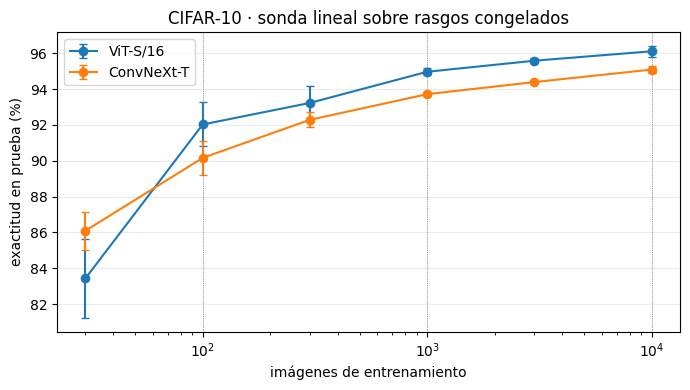

In [142]:
graficar_curva(df10, TAMANOS_PEDIDOS, "CIFAR-10 · sonda lineal sobre rasgos congelados")

## 5.6 · Panel con controles deslizantes: elige el tamaño y la semilla
El deslizador **tamaño** recorre los subconjuntos; el menú **semilla** muestra una semilla concreta o el promedio de las tres.

In [143]:
def panel_tamano(df):
    sl_n = widgets.SelectionSlider(options=sorted(df.n.unique()), value=1000, description="tamaño", continuous_update=False,
                                   style={"description_width": "60px"}, layout=widgets.Layout(width="420px"))
    dd_s = widgets.Dropdown(options=["promedio"] + SEMILLAS, value="promedio", description="semilla",
                            style={"description_width": "60px"})
    salida = widgets.Output()

    def dibujar(_=None):
        with salida:
            clear_output(wait=True)
            d = df[df.n == sl_n.value]
            fig, eje = plt.subplots(figsize=(5, 3.4))
            for k, m in enumerate(MODELOS):
                v = d[d.modelo == m].exactitud.values * 100
                alto = v.mean() if dd_s.value == "promedio" else d[(d.modelo == m) & (d.semilla == dd_s.value)].exactitud.iloc[0] * 100
                eje.bar(k, alto, color=COLORES[m], width=0.55)
                eje.scatter([k] * len(v), v, color="black", s=14, zorder=3)     # un punto por semilla
                eje.text(k, alto + 0.6, f"{alto:.1f}", ha="center")
            eje.set_xticks(range(len(MODELOS)))
            eje.set_xticklabels(list(MODELOS))
            eje.set_ylim(0, 105)
            eje.set_ylabel("exactitud en prueba (%)")
            eje.set_title(f"{sl_n.value} imágenes de entrenamiento")
            plt.tight_layout()
            plt.show()

    sl_n.observe(dibujar, "value")
    dd_s.observe(dibujar, "value")
    display(widgets.VBox([widgets.HBox([sl_n, dd_s]), salida]))
    dibujar()

In [144]:
panel_tamano(df10)

# 6 · ¿La diferencia entre el ViT y la CNN es real?
Con 3 semillas, una prueba t tendría solo 2 grados de libertad. Por eso usamos un **bootstrap sobre las 10000 imágenes de prueba**: se remuestrean las imágenes con reemplazo, se calcula en cada remuestreo la diferencia de exactitud ViT − ConvNeXt (promediada en las 3 semillas) y se toma el intervalo entre percentiles. Si el intervalo no contiene el cero, hay una diferencia clara; si lo contiene, no podemos decir que una arquitectura gane.

**Qué mide y qué no.** El bootstrap captura la incertidumbre por tener solo 10000 imágenes de prueba; no captura la variación por elegir otro subconjunto de entrenamiento (para eso están las desviaciones entre semillas de la sección 5).

## 6.1 · Función de bootstrap

In [145]:
def bootstrap_diferencia(preds, y_te, n, n_boot=N_BOOT, semilla=0):
    # Para cada imagen de prueba: fracción de semillas que acertó cada modelo
    ok_vit = np.stack([preds[("ViT-S/16", n, s)] == y_te for s in SEMILLAS]).mean(0)
    ok_cnn = np.stack([preds[("ConvNeXt-T", n, s)] == y_te for s in SEMILLAS]).mean(0)
    d = ok_vit - ok_cnn
    rng = np.random.default_rng(semilla)
    medias = np.empty(n_boot)
    for i in range(0, n_boot, 250):                    # por bloques para no gastar memoria
        k = min(250, n_boot - i)
        idx = rng.integers(0, len(d), (k, len(d)))
        medias[i:i + k] = d[idx].mean(1)
    return d.mean(), medias

In [146]:
def intervalo(medias, confianza=0.95):
    a = (1 - confianza) / 2 * 100
    return np.percentile(medias, [a, 100 - a])

## 6.2 · Diferencias e intervalos al 95 %

In [147]:
def tabla_bootstrap(preds, y_te, tamanos):
    filas, dist = [], {}
    for n in tamanos:
        dif, medias = bootstrap_diferencia(preds, y_te, n)
        lo, hi = intervalo(medias)
        veredicto = "ViT mejor" if lo > 0 else ("ConvNeXt mejor" if hi < 0 else "sin diferencia clara")
        filas.append({"n": n, "ViT − ConvNeXt (pp)": dif * 100, "IC95 inferior": lo * 100, "IC95 superior": hi * 100, "veredicto": veredicto})
        dist[n] = medias
    return pd.DataFrame(filas), dist

In [148]:
boot10, DIST10 = tabla_bootstrap(PRED10, yte, TAMANOS)
RESULTADOS["cifar10_bootstrap"] = boot10
print(boot10.round(2).to_string(index=False))

    n  ViT − ConvNeXt (pp)  IC95 inferior  IC95 superior      veredicto
   30                -2.66          -3.20          -2.12 ConvNeXt mejor
  100                 1.86           1.42           2.33      ViT mejor
  300                 0.94           0.50           1.39      ViT mejor
 1000                 1.25           0.85           1.64      ViT mejor
 3000                 1.19           0.82           1.60      ViT mejor
10000                 1.02           0.64           1.42      ViT mejor


## 6.3 · Diferencia ViT − ConvNeXt según el tamaño
Las barras son el intervalo de confianza al 95 %. Por encima del cero gana el ViT; por debajo, la CNN.

In [187]:
def graficar_diferencia(tabla, titulo, archivo=None):
    fig, eje = plt.subplots(figsize=(7, 3.6))
    x = np.arange(len(tabla))
    y = tabla["ViT − ConvNeXt (pp)"].values
    err = [y - tabla["IC95 inferior"].values, tabla["IC95 superior"].values - y]
    eje.errorbar(x, y, yerr=err, fmt="o", capsize=4, color="black")
    eje.axhline(0, color="red", lw=0.8)
    eje.set_xticks(x)
    eje.set_xticklabels(tabla["n"])
    eje.set_xlabel("imágenes de entrenamiento")
    eje.set_ylabel("ViT − ConvNeXt (puntos porcentuales)")
    eje.set_title(titulo)
    eje.grid(alpha=0.25)
    plt.tight_layout()
    if archivo:
        fig.savefig(archivo, dpi=150, bbox_inches="tight")
    plt.show()

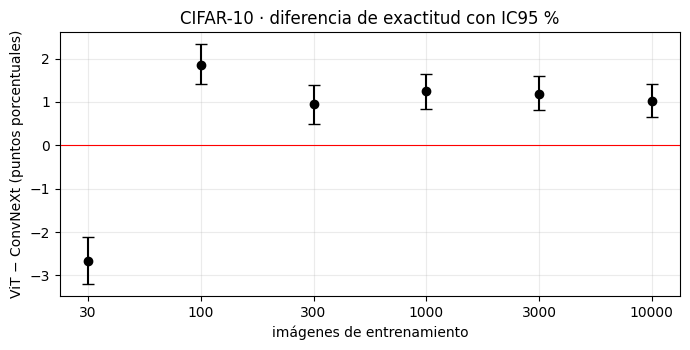

In [150]:
graficar_diferencia(boot10, "CIFAR-10 · diferencia de exactitud con IC95 %")

## 6.4 · Panel con controles deslizantes: tamaño y nivel de confianza
Cambia el tamaño y el nivel de confianza: a más confianza, el intervalo se ensancha y es más fácil que contenga el cero.

In [151]:
def panel_bootstrap(dist, tamanos):
    sl_n = widgets.SelectionSlider(options=tamanos, value=1000 if 1000 in tamanos else tamanos[0], description="tamaño",
                                   continuous_update=False, style={"description_width": "60px"}, layout=widgets.Layout(width="420px"))
    sl_c = widgets.FloatSlider(value=95, min=80, max=99, step=1, description="confianza %", continuous_update=False,
                               style={"description_width": "80px"}, layout=widgets.Layout(width="420px"))
    salida = widgets.Output()

    def dibujar(_=None):
        with salida:
            clear_output(wait=True)
            medias = dist[sl_n.value] * 100
            lo, hi = intervalo(medias, sl_c.value / 100)
            fig, eje = plt.subplots(figsize=(6, 3))
            eje.hist(medias, bins=40, color="#9ecae1")
            eje.axvline(0, color="red", lw=1)
            eje.axvline(lo, color="black", ls="--")
            eje.axvline(hi, color="black", ls="--")
            eje.set_xlabel("ViT − ConvNeXt (pp) en cada remuestreo")
            eje.set_title(f"n = {sl_n.value} · IC {sl_c.value:.0f} % = [{lo:.2f}, {hi:.2f}]")
            plt.tight_layout()
            plt.show()
            if lo > 0:
                print("Veredicto: el ViT es mejor con esta confianza.")
            elif hi < 0:
                print("Veredicto: la CNN es mejor con esta confianza.")
            else:
                print("Veredicto: el intervalo contiene el cero; no hay diferencia clara.")

    sl_n.observe(dibujar, "value")
    sl_c.observe(dibujar, "value")
    display(widgets.VBox([sl_n, sl_c, salida]))
    dibujar()

In [152]:
panel_bootstrap(DIST10, TAMANOS)

## 6.5 · ¿Gana el mismo modelo en las tres semillas?
El bootstrap no incluye la variación por el subconjunto de entrenamiento. Como control, se cuenta en cuántas de las 3 semillas el ViT supera a ConvNeXt con el mismo subconjunto. Con 3 semillas es un control tosco, pero no depende de ningún supuesto.

In [153]:
def semillas_donde_gana_vit(df):
    # Para cada tamaño: en cuántas semillas la exactitud del ViT supera a la de ConvNeXt (mismo subconjunto)
    p = df.pivot_table(index=["n", "semilla"], columns="modelo", values="exactitud")
    gana = (p["ViT-S/16"] > p["ConvNeXt-T"]).groupby("n").sum()
    return gana.rename("semillas donde gana el ViT").to_frame().assign(semillas=len(SEMILLAS))

semillas10 = semillas_donde_gana_vit(df10)
RESULTADOS["cifar10_semillas"] = semillas10.reset_index()
print(semillas10.to_string())

       semillas donde gana el ViT  semillas
n                                          
30                              0         3
100                             3         3
300                             2         3
1000                            3         3
3000                            3         3
10000                           3         3


# 7 · Un caso más difícil: CIFAR-100
En CIFAR-10 los modelos preentrenados pueden llegar a un techo cercano al 95-98 % y ocultar las diferencias (Touvron et al., 2022, p. 11, reporta 98.9 % al afinar un ViT-S en CIFAR-10). CIFAR-100 (Krizhevsky, 2009; https://huggingface.co/datasets/uoft-cs/cifar100) tiene 100 clases con imágenes del mismo tamaño, así que deja más margen. Los subconjuntos son balanceados: con 300 imágenes hay solo 3 por clase.

## 7.1 · Descargar y convertir CIFAR-100

In [154]:
cifar100 = load_dataset("uoft-cs/cifar100")
print(cifar100["train"].features.keys())

dict_keys(['img', 'fine_label', 'coarse_label'])


In [155]:
def a_arreglos100(particion):
    X = np.stack([np.array(im) for im in particion["img"]])
    y = np.array(particion["fine_label"])      # etiqueta de las 100 clases finas
    return X, y

Xtr100, ytr100 = a_arreglos100(cifar100["train"])
Xte100, yte100 = a_arreglos100(cifar100["test"])
print("Xtr100", Xtr100.shape, "| clases:", len(np.unique(ytr100)))

Xtr100 (50000, 32, 32, 3) | clases: 100


## 7.2 · Extraer rasgos de CIFAR-100
Otros dos o tres minutos aproximadamente.

In [156]:
FEATS100 = {}
for nombre, (modelo, cfg) in MOD.items():
    t0 = time.time()
    FEATS100[(nombre, "train")] = extraer(modelo, cfg, Xtr100)
    FEATS100[(nombre, "test")] = extraer(modelo, cfg, Xte100)
    print(nombre, "listo en", round(time.time() - t0, 1), "s")

ViT-S/16 listo en 81.8 s
ConvNeXt-T listo en 96.7 s


## 7.3 · Sondas lineales de CIFAR-100

In [157]:
TAMANOS100 = [300, 1000, 3000, 10000]
df100, PRED100, SONDAS100 = barrer(FEATS100, ytr100, yte100, 100, TAMANOS100)
RESULTADOS["cifar100_por_semilla"] = df100
resumen100 = tabla_resumen(df100)
RESULTADOS["cifar100_resumen"] = resumen100
print((resumen100.set_index("n") * 100).round(2).to_string())

       ViT-S/16 media  ViT-S/16 desv.  ConvNeXt-T media  ConvNeXt-T desv.  ViT − ConvNeXt
n                                                                                        
300             63.40            2.15             62.28              0.57            1.12
1000            74.63            0.12             72.41              0.26            2.22
3000            79.39            0.45             76.78              0.08            2.61
10000           82.51            0.17             80.12              0.05            2.39


In [158]:
boot100, DIST100 = tabla_bootstrap(PRED100, yte100, TAMANOS100)
RESULTADOS["cifar100_bootstrap"] = boot100
print(boot100.round(2).to_string(index=False))

    n  ViT − ConvNeXt (pp)  IC95 inferior  IC95 superior veredicto
  300                 1.12           0.53           1.75 ViT mejor
 1000                 2.22           1.63           2.80 ViT mejor
 3000                 2.61           1.99           3.20 ViT mejor
10000                 2.39           1.77           2.98 ViT mejor


## 7.4 · Curva y diferencia en CIFAR-100

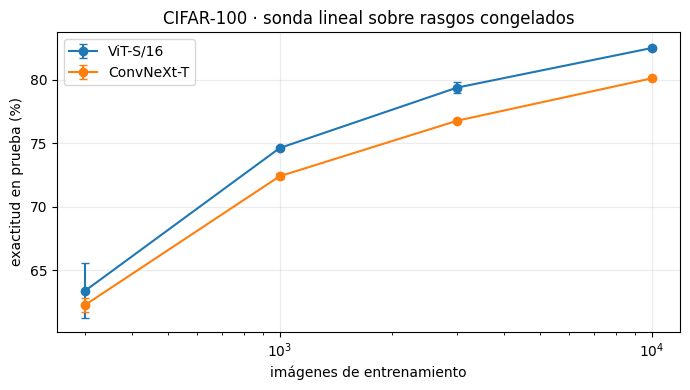

In [159]:
graficar_curva(df100, [], "CIFAR-100 · sonda lineal sobre rasgos congelados")

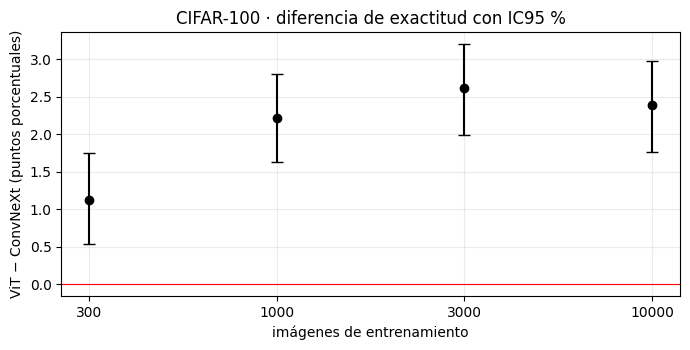

In [160]:
graficar_diferencia(boot100, "CIFAR-100 · diferencia de exactitud con IC95 %")

## 7.5 · Consistencia entre semillas en CIFAR-100

In [161]:
semillas100 = semillas_donde_gana_vit(df100)
RESULTADOS["cifar100_semillas"] = semillas100.reset_index()
print(semillas100.to_string())

       semillas donde gana el ViT  semillas
n                                          
300                             2         3
1000                            3         3
3000                            3         3
10000                           3         3


# 8 · ¿Dónde mira cada modelo? Mapas de atención frente a mapas de características
Un ViT y una CNN "miran" de maneras distintas, y por eso no se pueden dibujar con el mismo método:

- **ViT.** Tiene matrices de atención. Dibujamos el *attention rollout* (Abnar y Zuidema, 2020, pp. 3–4: se suma la identidad a la atención, A = 0.5·W + 0.5·I, y se multiplican las capas), que combina la atención de todas las capas teniendo en cuenta las conexiones residuales, y también la atención directa del token [CLS] en una capa y cabeza concretas.
- **CNN.** No tiene atención: lo que tiene son mapas de características (la salida de cada etapa). Dibujamos su magnitud y sus tres primeras componentes principales (PCA) como color.
- **Los dos.** Aplicamos **Grad-CAM** (Selvaraju et al., 2017, ec. 1, p. 4: pesos por promedio global de los gradientes y ReLU de la suma ponderada), que usa el gradiente de la clase elegida respecto a las activaciones y funciona igual en ambas arquitecturas. Aquí el "puntaje" de la clase es el de la sonda lineal entrenada en la sección 5, de modo que se puede ver cómo cambia el mapa según con cuántas imágenes se entrenó la sonda.

Rollout y Grad-CAM son anteriores a 2022; los incluimos como excepción acordada, porque son los métodos originales. Park y Kim (2022) usan además el análisis de Fourier de los mapas de características, que retomamos en la sección 8.6.

## 8.1 · Preparar los modelos y las funciones de captura

In [162]:
vit, cfg_vit = MOD["ViT-S/16"]
cnn, cfg_cnn = MOD["ConvNeXt-T"]

# La atención "fusionada" de timm no devuelve la matriz de atención: se desactiva para poder leerla
for bloque in vit.blocks:
    bloque.attn.fused_attn = False
N_CABEZAS = vit.blocks[0].attn.num_heads
print("bloques del ViT:", len(vit.blocks), "| cabezas por bloque:", N_CABEZAS, "| etapas de ConvNeXt:", len(cnn.stages))

bloques del ViT: 12 | cabezas por bloque: 6 | etapas de ConvNeXt: 4


In [163]:
def preparar(i):
    # Imagen de prueba i, agrandada a 224×224 y sin normalizar (sirve para dibujarla)
    x = torch.from_numpy(Xte[i]).permute(2, 0, 1).float().div(255)[None].to(DEVICE)
    return F.interpolate(x, size=224, mode="bicubic", align_corners=False).clamp(0, 1)

def normalizar(x, cfg):
    media = torch.tensor(cfg["mean"], device=DEVICE).view(1, 3, 1, 1)
    desv = torch.tensor(cfg["std"], device=DEVICE).view(1, 3, 1, 1)
    return (x - media) / desv

def capturar(modelo, capas, x_norm):
    # Pasa la imagen por el modelo y guarda la salida de cada capa de la lista
    salidas, ganchos = [], []
    for capa in capas:
        ganchos.append(capa.register_forward_hook(lambda m, i, o: salidas.append(o.detach().float().cpu())))
    with torch.no_grad():
        modelo(x_norm)
    for g in ganchos:
        g.remove()
    return salidas

## 8.2 · Attention rollout y mapas de características
El rollout se calcula así: en cada capa se promedia la atención de todas las cabezas, se suma la identidad (para representar la conexión residual) y se normaliza cada fila; el producto de las matrices de todas las capas dice cuánta información de cada parche llega al token [CLS].

In [164]:
def rollout(atenciones):
    # atenciones: lista de tensores (cabezas, N, N), una por capa
    n = atenciones[0].shape[-1]
    R = torch.eye(n)
    for A in atenciones:
        a = A.mean(0) + torch.eye(n)            # promedio de cabezas + conexión residual
        a = a / a.sum(-1, keepdim=True)         # cada fila vuelve a sumar 1
        R = a @ R                               # se acumula capa tras capa
    return R[0, 1:].reshape(14, 14)             # fila del [CLS] hacia los 14×14 parches

In [165]:
def mapa_pca(feat_hwc):
    # Resume los canales en 3 componentes principales y los usa como color RGB
    h, w, c = feat_hwc.shape
    X = feat_hwc.reshape(-1, c)
    X = X - X.mean(0)
    _, _, V = torch.pca_lowrank(X, q=3)
    P = X @ V[:, :3]
    P = (P - P.min(0).values) / (P.max(0).values - P.min(0).values + 1e-8)
    return P.reshape(h, w, 3)

In [166]:
def vista_vit(x_norm):
    # Todo lo que se dibuja del ViT para una imagen
    atenciones = [a[0] for a in capturar(vit, [b.attn.attn_drop for b in vit.blocks], x_norm)]   # (cabezas, 197, 197)
    bloques = capturar(vit, list(vit.blocks), x_norm)                                              # (1, 197, 384)
    return atenciones, bloques

def vista_cnn(x_norm):
    return capturar(cnn, list(cnn.stages), x_norm)                                                 # (1, C, H, W) por etapa

## 8.3 · Grad-CAM con la sonda lineal
Para el ViT usamos la entrada de la atención del último bloque (`blocks[-1].norm1`): en la salida del último bloque solo importa el token [CLS], así que los parches no tendrían gradiente. Para ConvNeXt usamos la salida de la última etapa (7×7). En los dos casos el gradiente es el de la puntuación de la clase en la sonda.

In [167]:
def logits_sonda(rasgos, s):
    # Puntaje de cada clase: estandarizar con los datos del entrenamiento y aplicar W y b de la sonda
    mu, sd, W, b = (s[k].to(DEVICE) for k in ("mu", "sd", "W", "b"))
    return ((rasgos - mu) / sd) @ W + b

In [168]:
def grad_cam(modelo, capa, x_norm, s, clase=None):
    # Devuelve el mapa Grad-CAM, la clase usada y las probabilidades de la sonda
    guardado = {}

    def gancho(modulo, entrada, salida):
        salida.retain_grad()                  # necesitamos el gradiente de esta activación
        guardado["a"] = salida

    g = capa.register_forward_hook(gancho)
    x = x_norm.clone().requires_grad_(True)  # sin esto no se arma el grafo: los pesos están congelados
    z = logits_sonda(modelo(x), s)
    clase = int(z.argmax(1)) if clase is None else clase
    z[0, clase].backward()
    g.remove()
    A, G = guardado["a"][0], guardado["a"].grad[0]
    if A.dim() == 2:                          # ViT: (tokens, canales) → solo parches, sin [CLS]
        A, G = A[1:], G[1:]
        cam = F.relu((A * G.mean(0)).sum(1)).reshape(14, 14)
    else:                                     # CNN: (canales, alto, ancho)
        cam = F.relu((A * G.mean((1, 2))[:, None, None]).sum(0))
    return cam.detach().cpu(), clase, z.softmax(1)[0].detach().cpu()

## 8.4 · Comprobar que todo corre con una imagen

In [169]:
x0 = preparar(0)
atenciones, bloques = vista_vit(normalizar(x0, cfg_vit))
etapas = vista_cnn(normalizar(x0, cfg_cnn))
R = rollout(atenciones)
cam_v, clase_v, p_v = grad_cam(vit, vit.blocks[-1].norm1, normalizar(x0, cfg_vit), SONDAS10[("ViT-S/16", 1000)])
cam_c, clase_c, p_c = grad_cam(cnn, cnn.stages[-1], normalizar(x0, cfg_cnn), SONDAS10[("ConvNeXt-T", 1000)])
print("atenciones por capa:", len(atenciones), atenciones[0].shape, "| rollout:", tuple(R.shape))
print("etapas de ConvNeXt:", [tuple(e.shape[1:]) for e in etapas])
print("Grad-CAM ViT:", tuple(cam_v.shape), "clase", CLASES[clase_v], "| Grad-CAM ConvNeXt:", tuple(cam_c.shape), "clase", CLASES[clase_c])
print("clase real de la imagen 0:", CLASES[yte[0]])

atenciones por capa: 12 torch.Size([6, 197, 197]) | rollout: (14, 14)
etapas de ConvNeXt: [(96, 56, 56), (192, 28, 28), (384, 14, 14), (768, 7, 7)]
Grad-CAM ViT: (14, 14) clase cat | Grad-CAM ConvNeXt: (7, 7) clase cat
clase real de la imagen 0: cat


## 8.5 · Panel con controles deslizantes: atención y mapas de características
- **imagen**: una de las primeras 200 imágenes de prueba.
- **capa ViT** y **cabeza**: qué capa y qué cabeza de atención se dibujan (cabeza 0 = promedio de las 6).
- **etapa CNN**: de la 1 (56×56, detalles finos) a la 4 (7×7, rasgos abstractos).
- **sonda con n**: con cuántas imágenes se entrenó la sonda que usa Grad-CAM.
- **opacidad**: cuánto se mezcla el mapa con la imagen.

In [170]:
def sobre_imagen(eje, img, mapa, alfa, titulo):
    # Dibuja el mapa (reescalado a 224×224 y normalizado) encima de la imagen
    eje.imshow(img)
    m = F.interpolate(mapa[None, None].float(), size=224, mode="bilinear", align_corners=False)[0, 0].numpy()
    m = (m - m.min()) / (m.max() - m.min() + 1e-8)
    eje.imshow(m, cmap="jet", alpha=alfa)
    eje.set_title(titulo, fontsize=9)
    eje.axis("off")

def solo_texto(eje, texto):
    eje.text(0.5, 0.5, texto, ha="center", va="center", fontsize=9, wrap=True)
    eje.axis("off")

In [171]:
def panel_visual():
    estilo = {"description_width": "110px"}
    ancho = widgets.Layout(width="440px")
    sl_img = widgets.IntSlider(value=0, min=0, max=199, description="imagen", continuous_update=False, style=estilo, layout=ancho)
    sl_capa = widgets.IntSlider(value=12, min=1, max=len(vit.blocks), description="capa ViT", continuous_update=False, style=estilo, layout=ancho)
    sl_cab = widgets.IntSlider(value=0, min=0, max=N_CABEZAS, description="cabeza (0=prom.)", continuous_update=False, style=estilo, layout=ancho)
    sl_et = widgets.IntSlider(value=4, min=1, max=len(cnn.stages), description="etapa CNN", continuous_update=False, style=estilo, layout=ancho)
    sl_n = widgets.SelectionSlider(options=TAMANOS, value=1000, description="sonda con n", continuous_update=False, style=estilo, layout=ancho)
    sl_a = widgets.FloatSlider(value=0.55, min=0.0, max=1.0, step=0.05, description="opacidad", continuous_update=False, style=estilo, layout=ancho)
    dd_c = widgets.Dropdown(options=["predicha"] + CLASES, value="predicha", description="clase objetivo", style=estilo)
    salida = widgets.Output()

    def dibujar(_=None):
        with salida:
            clear_output(wait=True)
            i = sl_img.value
            img = preparar(i)
            ver = img[0].permute(1, 2, 0).cpu().numpy()
            xv, xc = normalizar(img, cfg_vit), normalizar(img, cfg_cnn)
            atenciones, bloques = vista_vit(xv)
            etapas = vista_cnn(xc)
            clase = None if dd_c.value == "predicha" else CLASES.index(dd_c.value)
            cam_v, cl_v, p_v = grad_cam(vit, vit.blocks[-1].norm1, xv, SONDAS10[("ViT-S/16", sl_n.value)], clase)
            cam_c, cl_c, p_c = grad_cam(cnn, cnn.stages[-1], xc, SONDAS10[("ConvNeXt-T", sl_n.value)], clase)

            capa, cab, et, alfa = sl_capa.value, sl_cab.value, sl_et.value, sl_a.value
            A = atenciones[capa - 1]
            att = (A.mean(0) if cab == 0 else A[cab - 1])[0, 1:].reshape(14, 14)          # atención [CLS] → parches
            pca_v = mapa_pca(bloques[capa - 1][0, 1:].reshape(14, 14, -1))
            e = etapas[et - 1][0]                                                          # (C, H, W)
            pca_c = mapa_pca(e.permute(1, 2, 0))

            fig, ejes = plt.subplots(2, 5, figsize=(15, 6.4))
            # Fila 1: ViT
            ejes[0, 0].imshow(ver); ejes[0, 0].set_title(f"imagen · real: {CLASES[yte[i]]}", fontsize=9); ejes[0, 0].axis("off")
            sobre_imagen(ejes[0, 1], ver, rollout(atenciones), alfa, "ViT · rollout (todas las capas)")
            sobre_imagen(ejes[0, 2], ver, att, alfa, f"ViT · atención [CLS] capa {capa}, " + ("prom. de cabezas" if cab == 0 else f"cabeza {cab}"))
            ejes[0, 3].imshow(pca_v); ejes[0, 3].set_title(f"ViT · PCA de la capa {capa}", fontsize=9); ejes[0, 3].axis("off")
            sobre_imagen(ejes[0, 4], ver, cam_v, alfa, f"ViT · Grad-CAM ({CLASES[cl_v]}, p={p_v[cl_v]:.2f})")
            # Fila 2: ConvNeXt
            ejes[1, 0].imshow(ver); ejes[1, 0].set_title("imagen", fontsize=9); ejes[1, 0].axis("off")
            solo_texto(ejes[1, 1], "La CNN no tiene\nmatrices de atención")
            sobre_imagen(ejes[1, 2], ver, e.norm(dim=0), alfa, f"CNN · magnitud de la etapa {et} ({e.shape[1]}×{e.shape[2]})")
            ejes[1, 3].imshow(pca_c); ejes[1, 3].set_title(f"CNN · PCA de la etapa {et}", fontsize=9); ejes[1, 3].axis("off")
            sobre_imagen(ejes[1, 4], ver, cam_c, alfa, f"CNN · Grad-CAM ({CLASES[cl_c]}, p={p_c[cl_c]:.2f})")
            plt.tight_layout()
            plt.show()

    for w in (sl_img, sl_capa, sl_cab, sl_et, sl_n, sl_a, dd_c):
        w.observe(dibujar, "value")
    display(widgets.VBox([sl_img, widgets.HBox([sl_capa, sl_cab]), widgets.HBox([sl_et, sl_n]), widgets.HBox([sl_a, dd_c]), salida]))
    dibujar()

In [172]:
panel_visual()

## 8.6 · Qué frecuencias conserva cada arquitectura (análisis de Fourier)
Park y Kim (2022, sec. 3 y apéndice A.2, p. 16) miden la diferencia entre la amplitud logarítmica de la frecuencia más alta (1.0π) y la de frecuencia cero en los mapas de características, a lo largo de la profundidad. Concluyen que las capas de atención actúan como filtros pasa-bajos y las convoluciones como pasa-altos, en redes entrenadas desde cero.

Aquí repetimos la medición con los modelos preentrenados, con tres diferencias respecto de su procedimiento que hay que tener presentes: usamos 512 imágenes de prueba (ellos usan todo el conjunto de prueba), una ventana de frecuencias de ±0.125π (ellos usan 0.1π; con mapas de 7×7 una ventana más estrecha queda vacía) y la salida de cada bloque completo (ellos separan atención y MLP). Se grafican cuatro frecuencias, no solo 1.0π, y se toman los 12 bloques del ViT y los 18 bloques de ConvNeXt.

Una curva que baja con la profundidad significa que esa frecuencia pierde peso respecto de la media del mapa. Es una descripción de estos pesos concretos, no una prueba de que la atención suavice ni de que la convolución realce.

In [173]:
FRECUENCIAS = [0.25, 0.5, 0.75, 1.0]      # fracción de la frecuencia máxima (π)
VENTANA = 0.125                           # semiancho del anillo de frecuencias, en fracción de π
N_IMG_ESPECTRO = 512                      # imágenes de prueba usadas para promediar el espectro

def delta_log_amplitud(mapa):
    # mapa: (B, C, H, W). Devuelve log(amplitud en f) − log(amplitud en f = 0) para cada frecuencia
    B, Cn, H, W = mapa.shape
    amp = torch.fft.fft2(mapa).abs()
    fy = torch.fft.fftfreq(H).view(H, 1)
    fx = torch.fft.fftfreq(W).view(1, W)
    radio = torch.sqrt(fy ** 2 + fx ** 2) / 0.5          # 1.0 = frecuencia de Nyquist
    dc = amp[:, :, 0, 0].mean()
    res = []
    for f in FRECUENCIAS:
        anillo = (radio >= f - VENTANA) & (radio < f + VENTANA)
        res.append((torch.log(amp[:, :, anillo].mean()) - torch.log(dc)).item())
    return res

In [174]:
def espectro_por_capa(imagenes, lote=16):
    # Para cada capa guarda Δ log amplitud promediado en lotes de imágenes
    vit_acum, cnn_acum, n_lotes = None, None, 0
    for i in range(0, len(imagenes), lote):
        x = torch.cat([preparar(j) for j in imagenes[i:i + lote]])
        bl = capturar(vit, list(vit.blocks), normalizar(x, cfg_vit))
        cb = capturar(cnn, [b for et in cnn.stages for b in et.blocks], normalizar(x, cfg_cnn))
        v = np.array([delta_log_amplitud(t[:, 1:].permute(0, 2, 1).reshape(len(t), -1, 14, 14)) for t in bl])
        c = np.array([delta_log_amplitud(t) for t in cb])
        vit_acum = v if vit_acum is None else vit_acum + v
        cnn_acum = c if cnn_acum is None else cnn_acum + c
        n_lotes += 1
    return vit_acum / n_lotes, cnn_acum / n_lotes

In [175]:
ESPECTRO_VIT, ESPECTRO_CNN = espectro_por_capa(list(range(N_IMG_ESPECTRO)))
print("ViT:", ESPECTRO_VIT.shape, "(capas × frecuencias) | ConvNeXt:", ESPECTRO_CNN.shape)

ViT: (12, 4) (capas × frecuencias) | ConvNeXt: (18, 4)


In [188]:
def graficar_espectro(frecuencia_idx=None, archivo=None):
    # Si frecuencia_idx es None dibuja las 4 frecuencias; si no, solo la elegida
    fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
    for eje, esp, titulo, color in ((ejes[0], ESPECTRO_VIT, "ViT-S/16 (12 bloques)", COLORES["ViT-S/16"]),
                                    (ejes[1], ESPECTRO_CNN, "ConvNeXt-T (18 bloques)", COLORES["ConvNeXt-T"])):
        x = np.arange(1, len(esp) + 1) / len(esp)           # profundidad relativa
        for k, f in enumerate(FRECUENCIAS):
            if frecuencia_idx is None or frecuencia_idx == k:
                eje.plot(x, esp[:, k], marker="o", ms=3, label=f"{f}π", alpha=0.9 if frecuencia_idx is not None else 0.7,
                         color=color if frecuencia_idx is not None else None)
        eje.set_title(titulo)
        eje.set_xlabel("profundidad relativa")
        eje.grid(alpha=0.25)
        eje.legend(title="frecuencia")
    ejes[0].set_ylabel("Δ log amplitud (f − 0)")
    plt.tight_layout()
    if archivo:
        fig.savefig(archivo, dpi=150, bbox_inches="tight")
    plt.show()

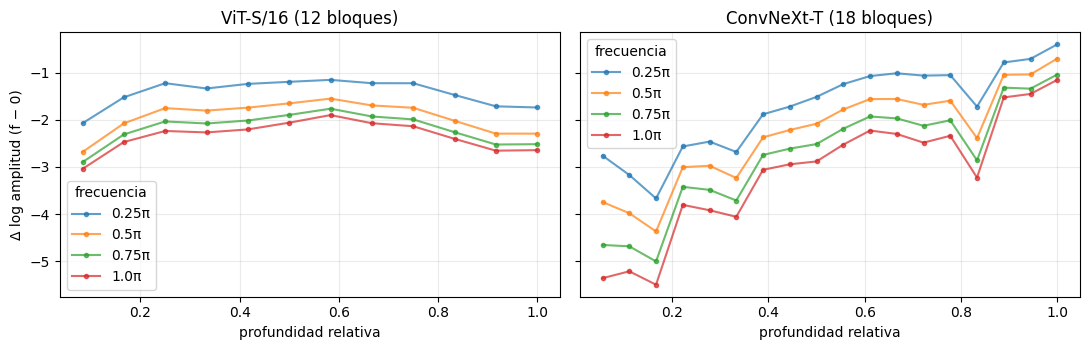

In [177]:
graficar_espectro()

Los mismos valores en una tabla: Δ log amplitud en el primer y el último bloque, y el cambio entre ambos, para cada frecuencia.

In [189]:
filas = []
for nombre, esp in (("ViT-S/16", ESPECTRO_VIT), ("ConvNeXt-T", ESPECTRO_CNN)):
    for k, f in enumerate(FRECUENCIAS):
        filas.append({"modelo": nombre, "frecuencia": f"{f}π", "primer bloque": esp[0, k], "último bloque": esp[-1, k], "cambio": esp[-1, k] - esp[0, k]})
tabla_espectro = pd.DataFrame(filas)
RESULTADOS["espectro"] = tabla_espectro
print(tabla_espectro.round(2).to_string(index=False))

    modelo frecuencia  primer bloque  último bloque  cambio
  ViT-S/16      0.25π          -2.07          -1.74    0.34
  ViT-S/16       0.5π          -2.68          -2.29    0.39
  ViT-S/16      0.75π          -2.90          -2.52    0.38
  ViT-S/16       1.0π          -3.04          -2.64    0.40
ConvNeXt-T      0.25π          -2.76          -0.39    2.37
ConvNeXt-T       0.5π          -3.75          -0.69    3.05
ConvNeXt-T      0.75π          -4.66          -1.03    3.62
ConvNeXt-T       1.0π          -5.36          -1.15    4.22


Lectura de la tabla. En ConvNeXt la frecuencia más alta gana peso frente a la frecuencia cero a lo largo de la profundidad (de -5.36 a -1.15, un cambio de +4.22), lo que va en el sentido que Park y Kim describen para las convoluciones. En el ViT el cambio es pequeño y también positivo (de -3.04 a -2.64, +0.40), es decir, **no** se observa el filtrado pasa-bajos que ellos reportan para los transformers entrenados desde cero. Hay varias diferencias que podrían explicarlo, sin que las hayamos probado: los pesos son preentrenados con otra receta, medimos la salida del bloque completo (con la conexión residual) y no solo la atención, y la ventana de frecuencias es más ancha. Por eso este análisis se deja como descripción y no como evidencia a favor o en contra de Park y Kim.

## 8.7 · Panel con controles deslizantes: una frecuencia a la vez

In [178]:
def panel_espectro():
    sl = widgets.SelectionSlider(options=[(f"{f}π", k) for k, f in enumerate(FRECUENCIAS)], value=1, description="frecuencia",
                                 continuous_update=False, style={"description_width": "80px"}, layout=widgets.Layout(width="420px"))
    salida = widgets.Output()

    def dibujar(_=None):
        with salida:
            clear_output(wait=True)
            graficar_espectro(sl.value)

    sl.observe(dibujar, "value")
    display(widgets.VBox([sl, salida]))
    dibujar()

In [179]:
panel_espectro()

# 9 · Chequeos de consistencia
Antes de interpretar, comprobamos que las piezas hacen lo que decimos que hacen. Si algo falla, el notebook se detiene aquí con un mensaje.

## 9.1 · Chequeos sobre datos, modelos y sondas

In [180]:
# 1) Los subconjuntos son balanceados: n/10 imágenes por clase en CIFAR-10
for n in [100, 1000, 10000]:
    idx = muestrear(ytr, n, 0)
    cuentas = np.bincount(ytr[idx], minlength=10)
    assert len(idx) == n and cuentas.min() == cuentas.max() == n // 10, f"subconjunto n={n} no balanceado"

# 2) Semillas distintas dan subconjuntos distintos
assert set(muestrear(ytr, 1000, 0)) != set(muestrear(ytr, 1000, 1)), "las semillas repiten el subconjunto"

# 3) Los rasgos no tienen NaN ni infinitos
for clave, M in FEATS.items():
    assert torch.isfinite(torch.as_tensor(M)).all(), f"rasgos no finitos en {clave}"

# 4) Parámetros del extractor (sin cabeza de clasificación), según la tabla de la sección 3
p = tabla_modelos.set_index("modelo")["parámetros (M)"]
assert abs(p["ViT-S/16"] - 21.67) < 0.05 and abs(p["ConvNeXt-T"] - 27.82) < 0.05, "parámetros distintos a los reportados"

# 5) Exactitudes dentro de [0, 1] y mejores que el azar
assert df10["exactitud"].between(0, 1).all() and (df10["exactitud"] > 0.1).all()
assert df100["exactitud"].between(0, 1).all() and (df100["exactitud"] > 0.01).all()

# 6) Cada tamaño tiene una fila por semilla y modelo
assert (df10.groupby(["n", "modelo"]).size() == len(SEMILLAS)).all()
print("chequeos de datos, modelos y sondas: correctos")

chequeos de datos, modelos y sondas: correctos


## 9.2 · Chequeos sobre las visualizaciones

In [181]:
# El rollout parte de matrices con filas que suman 1, así que el producto también las suma 1
n_tok = atenciones[0].shape[-1]
Rtotal = torch.eye(n_tok)
for A in atenciones:
    a = A.mean(0) + torch.eye(n_tok)
    a = a / a.sum(-1, keepdim=True)
    Rtotal = a @ Rtotal
assert torch.allclose(Rtotal.sum(-1), torch.ones(n_tok), atol=1e-3), "las filas del rollout no suman 1"

# La atención de cada cabeza también suma 1 por fila
assert torch.allclose(atenciones[0].sum(-1), torch.ones(atenciones[0].shape[:2]), atol=1e-3)

# Grad-CAM: sin NaN y con algún valor positivo
for nombre, cam in (("ViT", cam_v), ("ConvNeXt", cam_c)):
    assert torch.isfinite(cam).all() and cam.max() > 0, f"Grad-CAM de {nombre} vacío o con NaN"

# Los espectros tienen la forma esperada y son finitos
assert ESPECTRO_VIT.shape == (12, 4) and ESPECTRO_CNN.shape == (18, 4)
assert np.isfinite(ESPECTRO_VIT).all() and np.isfinite(ESPECTRO_CNN).all()
print("chequeos de visualización: correctos")

chequeos de visualización: correctos


## 9.3 · Penalización elegida por la validación cruzada
La primera versión usaba una rejilla de 5 valores (de 1e-4 a 1) y con n=30 todas las sondas elegían el valor más bajo. Se amplió a 8 valores (de 1e-6 a 10) y se volvió a ejecutar todo. La tabla cuenta cuántas veces se eligió cada valor.

In [182]:
# Cuántas veces se eligió cada lambda, por modelo, en CIFAR-10 y CIFAR-100
conteo = pd.concat([df10.assign(conjunto="CIFAR-10"), df100.assign(conjunto="CIFAR-100")]).groupby(["conjunto", "modelo", "lambda"]).size().unstack(fill_value=0)
print(conteo.to_string())
extremos = {min(LAMBDAS), max(LAMBDAS)}
en_borde = pd.concat([df10, df100])["lambda"].isin(extremos).mean()
print("\nfracción de sondas con lambda en el borde de la rejilla:", round(en_borde, 2))

lambda                0.000001   0.000010   0.000100   0.001000   0.010000   0.100000   1.000000   10.000000
conjunto  modelo                                                                                            
CIFAR-10  ConvNeXt-T          6          0          1          0          7          3          1          0
          ViT-S/16            5          0          0          0          5          6          1          1
CIFAR-100 ConvNeXt-T          2          3          1          1          3          2          0          0
          ViT-S/16            2          0          1          1          5          2          1          0

fracción de sondas con lambda en el borde de la rejilla: 0.27


Lectura. Con la rejilla ampliada, el 27 % de las sondas sigue eligiendo un extremo, y casi siempre es 1e-6, que en la práctica equivale a no penalizar. Ampliar la rejilla cambió los resultados con n=30, 100 y 300 (con n=300 el ViT pasó de 93.87 % a 93.23 % en CIFAR-10), sin invertir ningún veredicto de CIFAR-10, y no cambió los de n≥1000. En CIFAR-100 con n=300 el resultado pasó de empate a ventaja del ViT (+1.12 pp). Con 3 imágenes por clase la elección de λ por validación cruzada es inestable, y las conclusiones para n≤300 deben leerse con esa cautela.

# 10 · Interpretación y límites

## 10.1 · Resumen numérico para decidir
Una tabla compacta con el tamaño, la diferencia ViT − ConvNeXt y su intervalo de confianza, para CIFAR-10 y CIFAR-100.

In [183]:
def tabla_decision(boot, nombre):
    t = boot.copy()
    t.insert(0, "conjunto", nombre)
    return t

decision = pd.concat([tabla_decision(boot10, "CIFAR-10"), tabla_decision(boot100, "CIFAR-100")], ignore_index=True)
RESULTADOS["decision"] = decision
print(decision.round(2).to_string(index=False))

 conjunto     n  ViT − ConvNeXt (pp)  IC95 inferior  IC95 superior      veredicto
 CIFAR-10    30                -2.66          -3.20          -2.12 ConvNeXt mejor
 CIFAR-10   100                 1.86           1.42           2.33      ViT mejor
 CIFAR-10   300                 0.94           0.50           1.39      ViT mejor
 CIFAR-10  1000                 1.25           0.85           1.64      ViT mejor
 CIFAR-10  3000                 1.19           0.82           1.60      ViT mejor
 CIFAR-10 10000                 1.02           0.64           1.42      ViT mejor
CIFAR-100   300                 1.12           0.53           1.75      ViT mejor
CIFAR-100  1000                 2.22           1.63           2.80      ViT mejor
CIFAR-100  3000                 2.61           1.99           3.20      ViT mejor
CIFAR-100 10000                 2.39           1.77           2.98      ViT mejor


## 10.2 · Qué se puede afirmar
Con extractores preentrenados y congelados y una sonda lineal, evaluando en las 10000 imágenes de prueba de CIFAR-10, el resultado es este. Con 30 imágenes de entrenamiento (3 por clase) gana ConvNeXt-T: 86.09 % frente a 83.43 %, una diferencia de -2.66 puntos porcentuales (pp) con IC95 de -3.20 a -2.12, y gana en las 3 semillas. Desde 100 imágenes gana ViT-S/16 en todos los tamaños probados: +1.86 pp con n=100, +1.25 pp con n=1000 y +1.02 pp con n=10000, y ningún intervalo incluye el cero. Con n=300 la ventaja es la menor (+0.94 pp) y el ViT gana en 2 de 3 semillas; en los demás tamaños desde 100 gana en las 3. La ventaja se reduce al crecer n, pero no desaparece en el rango probado.

En CIFAR-100 (más difícil) el ViT gana en todos los tamaños probados: +1.12 pp con n=300 (IC95 de 0.53 a 1.75, 2 de 3 semillas) y +2.22, +2.61 y +2.39 pp con n=1000, 3000 y 10000. Con la rejilla de λ original, n=300 había salido como empate, de modo que ese veredicto depende de la penalización elegida (sección 9.3).

Para este tipo de uso, es decir, un backbone preentrenado con solo una capa lineal entrenada, los números sugieren ViT-S/16 desde unos 100 ejemplos y ConvNeXt-T solo con muy pocos (alrededor de 30) en una tarea de 10 clases. Entre 30 y 100 imágenes no se probaron tamaños intermedios, así que el punto de cruce está en ese intervalo.

## 10.3 · Qué no se puede afirmar
No se probó entrenar desde cero. La literatura de datos pequeños (Lu et al., 2022; Zhang et al., 2025; Rostand et al., 2025) trata ese caso, en el que los ViT sin ayuda suelen quedar por debajo de las CNN. Aquí los dos modelos ya vieron ImageNet-21k/22k, así que el resultado habla de la calidad de la representación preentrenada y no de la arquitectura por sí sola.

Tampoco se puede separar la arquitectura de la receta: ViT-S/16 usa los pesos AugReg (Steiner et al., 2021) y ConvNeXt-T los de la receta de Liu et al. (2022). Además es un solo par de modelos de tamaño parecido (21.67 M y 27.82 M de parámetros sin cabeza) y un solo tipo de imagen, 32×32 agrandada a 224×224.

Los intervalos de confianza son parciales. El bootstrap remuestrea las imágenes de prueba pero no la elección del subconjunto de entrenamiento, que solo se repitió con 3 semillas; con 2 grados de libertad una prueba t sería poco confiable, y por eso no se usó. Como control se cuenta en cuántas semillas gana cada modelo (secciones 6.5 y 7.5). La penalización de la sonda se eligió en una rejilla de 8 valores y en el 27 % de las sondas quedó en un extremo (sección 9.3); con 3 imágenes por clase esa elección es inestable.

Por último, rollout, Grad-CAM y el análisis de Fourier son herramientas para inspeccionar casos con los controles de la sección 8. No se cuantificó si los mapas son correctos y no deben leerse como la explicación causal de la diferencia de exactitud. El análisis de Fourier no reproduce el filtrado pasa-bajos del ViT que describen Park y Kim (2022), y difiere de su procedimiento (sección 8.6).

# 11 · Guardar resultados
Se guardan las tablas en CSV y las figuras principales en PNG, y se comprimen en un solo archivo para llevarlas a la carpeta `resultados` del proyecto.

Las columnas de exactitud de los CSV están en fracción (0 a 1); las diferencias de las tablas de bootstrap y de decisión, en puntos porcentuales.

In [190]:
import os, zipfile
os.makedirs("resultados_s14", exist_ok=True)

# Una tabla por archivo
for nombre, tabla in RESULTADOS.items():
    tabla.to_csv(f"resultados_s14/{nombre}.csv", index=False)
print(sorted(os.listdir("resultados_s14")))

['cifar100_bootstrap.csv', 'cifar100_por_semilla.csv', 'cifar100_resumen.csv', 'cifar100_semillas.csv', 'cifar10_bootstrap.csv', 'cifar10_por_semilla.csv', 'cifar10_resumen.csv', 'cifar10_semillas.csv', 'curva_cifar10.png', 'decision.csv', 'diferencia_cifar10.png', 'diferencia_cifar100.png', 'eficiencia.csv', 'espectro.csv', 'modelos.csv']


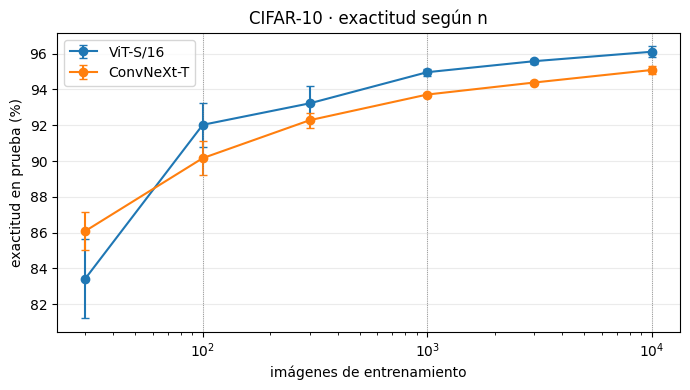

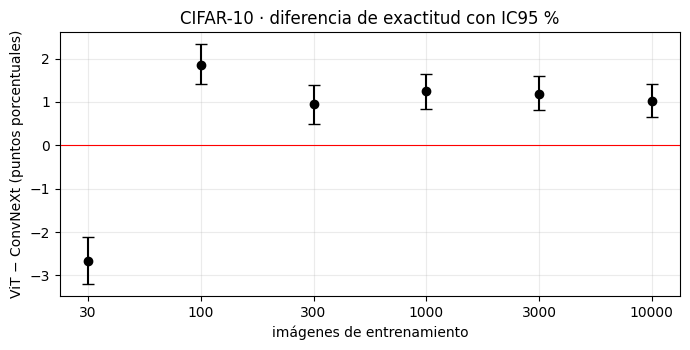

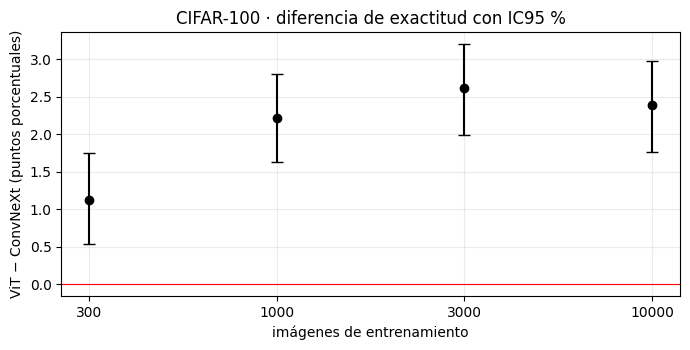

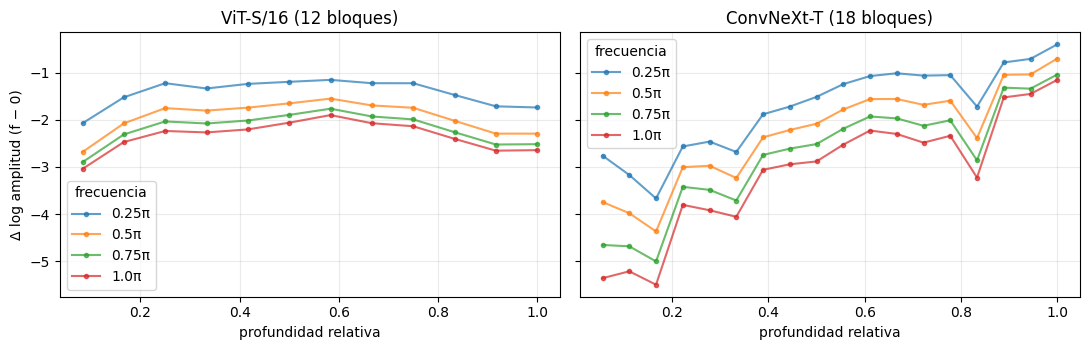

['cifar100_bootstrap.csv', 'cifar100_por_semilla.csv', 'cifar100_resumen.csv', 'cifar100_semillas.csv', 'cifar10_bootstrap.csv', 'cifar10_por_semilla.csv', 'cifar10_resumen.csv', 'cifar10_semillas.csv', 'curva_cifar10.png', 'decision.csv', 'diferencia_cifar10.png', 'diferencia_cifar100.png', 'eficiencia.csv', 'espectro.csv', 'espectro_fourier.png', 'modelos.csv']


In [191]:
# Figuras principales en PNG: la función las guarda antes de mostrarlas
graficar_curva(df10, TAMANOS_PEDIDOS, "CIFAR-10 · exactitud según n", archivo="resultados_s14/curva_cifar10.png")
graficar_diferencia(boot10, "CIFAR-10 · diferencia de exactitud con IC95 %", archivo="resultados_s14/diferencia_cifar10.png")
graficar_diferencia(boot100, "CIFAR-100 · diferencia de exactitud con IC95 %", archivo="resultados_s14/diferencia_cifar100.png")
graficar_espectro(archivo="resultados_s14/espectro_fourier.png")
print(sorted(os.listdir("resultados_s14")))

In [192]:
# Comprimir todo y ofrecer la descarga
with zipfile.ZipFile("resultados_s14.zip", "w", zipfile.ZIP_DEFLATED) as z:
    for archivo in os.listdir("resultados_s14"):
        z.write(os.path.join("resultados_s14", archivo), archivo)

from google.colab import files
files.download("resultados_s14.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# 12 · Fuentes
Formato APA 7.ª edición, solo con las fuentes citadas en este cuaderno. Los DOI se incluyen solo cuando se verificaron en el propio PDF; en los demás casos se da la dirección oficial de la publicación. Abnar y Zuidema (2020), Selvaraju et al. (2017) y Steiner et al. (2021) son anteriores a 2022 y se usan como excepción acordada, porque son los métodos originales de rollout y Grad-CAM y la fuente de los pesos del ViT.

Abnar, S., y Zuidema, W. (2020). Quantifying attention flow in transformers. En *Proceedings of the 58th Annual Meeting of the Association for Computational Linguistics* (pp. 4190–4197). Association for Computational Linguistics. https://arxiv.org/abs/2005.00928

Liu, Z., Mao, H., Wu, C.-Y., Feichtenhofer, C., Darrell, T., y Xie, S. (2022). A ConvNet for the 2020s. En *Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition* (pp. 11966–11976). https://openaccess.thecvf.com/content/CVPR2022/papers/Liu_A_ConvNet_for_the_2020s_CVPR_2022_paper.pdf

Lu, Z., Xie, H., Liu, C., y Zhang, Y. (2022). Bridging the gap between vision transformers and convolutional neural networks on small datasets. *Advances in Neural Information Processing Systems, 35*. https://papers.neurips.cc/paper_files/paper/2022/file/5e0b46975d1bfe6030b1687b0ada1b85-Paper-Conference.pdf

Park, N., y Kim, S. (2022). How do vision transformers work? *10th International Conference on Learning Representations (ICLR 2022)*. https://arxiv.org/abs/2202.06709

Rostand, J., Hsu, C.-C. J., y Lu, C.-K. (2025). Adaptive locality guidance: Using locality guidance to initialize the learning of vision transformers on tiny datasets. *IEEE Transactions on Neural Networks and Learning Systems, 36*(8). https://doi.org/10.1109/TNNLS.2024.3515076

Selvaraju, R. R., Cogswell, M., Das, A., Vedantam, R., Parikh, D., y Batra, D. (2017). Grad-CAM: Visual explanations from deep networks via gradient-based localization. En *Proceedings of the IEEE International Conference on Computer Vision* (pp. 618–626). https://arxiv.org/abs/1610.02391

Steiner, A., Kolesnikov, A., Zhai, X., Wightman, R., Uszkoreit, J., y Beyer, L. (2021). *How to train your ViT? Data, augmentation, and regularization in vision transformers*. arXiv. https://arxiv.org/abs/2106.10270

Touvron, H., Cord, M., El-Nouby, A., Verbeek, J., y Jégou, H. (2022). Three things everyone should know about vision transformers. En *Lecture Notes in Computer Science: Vol. 13684. Computer Vision – ECCV 2022* (pp. 497–515). https://arxiv.org/abs/2203.09795

Wang, Y., Tang, S., Zhu, F., Bai, L., Zhao, R., Qi, D., y Ouyang, W. (2022). Revisiting the transferability of supervised pretraining: An MLP perspective. En *Proceedings of the IEEE/CVF Conference on Computer Vision and Pattern Recognition* (pp. 9173–9183). https://openaccess.thecvf.com

Zhang, T., Xu, W., Luo, B., y Wang, G. (2025). Depth-wise convolutions in vision transformers for efficient training on small datasets. *Neurocomputing, 617*, Artículo 128998. https://doi.org/10.1016/j.neucom.2024.128998

Krizhevsky, A. (2009). *Learning multiple layers of features from tiny images* [Informe técnico]. University of Toronto. https://www.cs.toronto.edu/~kriz/cifar.html

Wightman, R. (2019). *PyTorch image models* [Software]. GitHub. https://doi.org/10.5281/zenodo.4414861

**Datos y pesos usados.** CIFAR-10: https://huggingface.co/datasets/uoft-cs/cifar10. CIFAR-100: https://huggingface.co/datasets/uoft-cs/cifar100. ViT-S/16: https://huggingface.co/timm/vit_small_patch16_224.augreg_in21k_ft_in1k (`vit_small_patch16_224.augreg_in21k_ft_in1k`). ConvNeXt-T: https://huggingface.co/timm/convnext_tiny.fb_in22k_ft_in1k (`convnext_tiny.fb_in22k_ft_in1k`). Material de clase: Clase 14, lámina 99.